# Explaining one prediction: LIME and SHAP

A court uses an opaque gradient boosting model that predicts whether a defendant is rearrested
within two years. The model gives one defendant a high risk. **Which features were most
influential for this one prediction?**

- *Feature importance* (project 03) is about the whole model.
- *Feature influence* (this notebook) is about a single prediction.

In [1]:
import warnings

import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from recidivism_data import load, load_xy, onehot, true_logit
from recidivism_data.shared import new_gbm, opaque_model, person
from recidivism_data.theme import BLUE, INK, MUTED, ORANGE, use_theme
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")
use_theme()

X_train, y_train = load_xy("train")
X_test, y_test = load_xy("test")
A_train, A_test = onehot(X_train), onehot(X_test)
names = list(A_train.columns)
model = opaque_model()
gbm = model[-1]  # the boosting model, on the encoded features

one = person()
one_encoded = onehot(one)
print(one.T.to_string(header=False))
print(f"\nmodel: P(rearrest) = {model.predict_proba(one)[0, 1]:.2f}")

age                      24
sex                    male
priors_count              5
juvenile_priors           0
age_at_first_arrest      17
charge_degree        felony
charge_type            drug
employed                  0
in_treatment              0
county                south

model: P(rearrest) = 0.69


## 1. LIME by hand, in two dimensions

LIME explains a prediction with a **local surrogate**: a linear model that is only valid near
the person. To see it, we use a model with only two features, `age` and `priors_count`.

1. Take many other inputs.
2. Ask the opaque model for its prediction for each.
3. Give each input a weight: near the person is important, far away is not.
4. Fit a weighted linear model. Its coefficients are the explanation.

In [2]:
two = ["age", "priors_count"]
gbm2 = new_gbm().fit(X_train[two], y_train)
center = one[two].to_numpy(float)[0]
scale = X_train[two].std().to_numpy()

rng = np.random.default_rng(0)
samples = X_train[two].sample(600, random_state=0).to_numpy(float)  # step 1
predictions = gbm2.predict_proba(samples)[:, 1]  # step 2
distance = np.sqrt((((samples - center) / scale) ** 2).sum(axis=1))
weights = np.exp(-(distance**2) / 0.75**2)  # step 3
local = Ridge(alpha=1.0).fit(samples - center, predictions, sample_weight=weights)  # step 4

print(f"opaque model at the person: {gbm2.predict_proba([center])[0, 1]:.2f}")
print(
    f"local linear model:         {local.intercept_:.2f} {local.coef_[0]:+.3f} per year of age {local.coef_[1]:+.3f} per prior"
)

opaque model at the person: 0.63
local linear model:         0.65 -0.016 per year of age +0.044 per prior


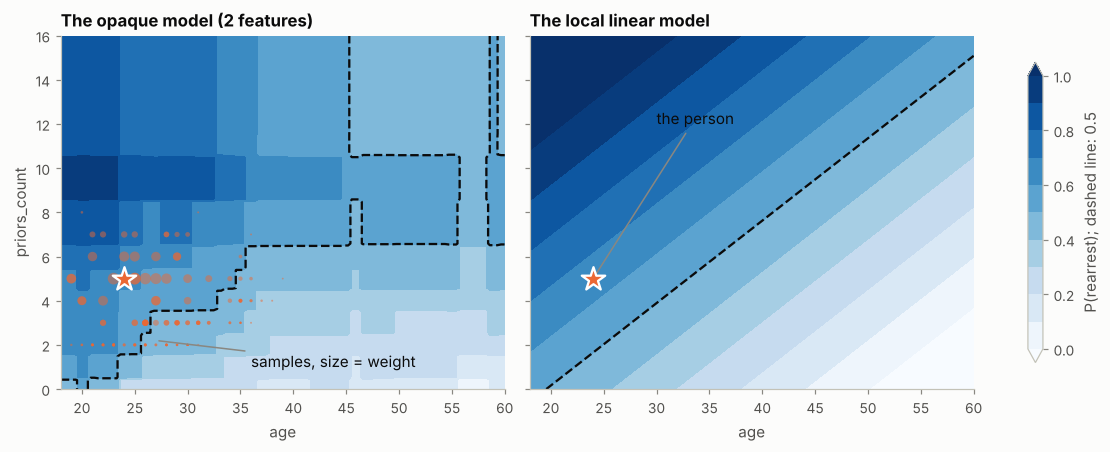

In [3]:
grid_age, grid_priors = np.meshgrid(np.linspace(18, 60, 120), np.linspace(0, 16, 120))
grid = np.column_stack([grid_age.ravel(), grid_priors.ravel()])
surface = gbm2.predict_proba(grid)[:, 1].reshape(grid_age.shape)
plane = local.predict(grid - center).reshape(grid_age.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, values, title in [
    (axes[0], surface, "The opaque model (2 features)"),
    (axes[1], plane, "The local linear model"),
]:
    filled = ax.contourf(
        grid_age, grid_priors, values, levels=np.linspace(0, 1, 11), cmap="Blues", extend="both"
    )
    ax.contour(
        grid_age, grid_priors, values, levels=[0.5], colors=INK, linewidths=1.5, linestyles="--"
    )
    ax.scatter(*center, marker="*", s=260, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=4)
    ax.set(title=title, xlabel="age", xlim=(18, 60), ylim=(0, 16))
    ax.grid(visible=False)
near = weights > 0.02
axes[0].scatter(
    samples[near, 0], samples[near, 1], s=weights[near] * 60, color=ORANGE, alpha=0.5, linewidth=0
)
axes[0].set_ylabel("priors_count")
axes[1].annotate(
    "the person", center, xytext=(30, 12), color=INK, arrowprops={"arrowstyle": "-", "color": MUTED}
)
axes[0].annotate(
    "samples, size = weight",
    (27, 2.2),
    xytext=(36, 1),
    color=INK,
    arrowprops={"arrowstyle": "-", "color": MUTED},
)
fig.colorbar(filled, ax=axes, label="P(rearrest); dashed line: 0.5", shrink=0.85)
plt.show()

Near the person, the plane is a good description: younger is worse, more priors is worse. Far
from the person it is wrong, e.g. it does not know that the effect of age becomes small after
35. **The explanation is local.**

## 2. LIME with the library, all features

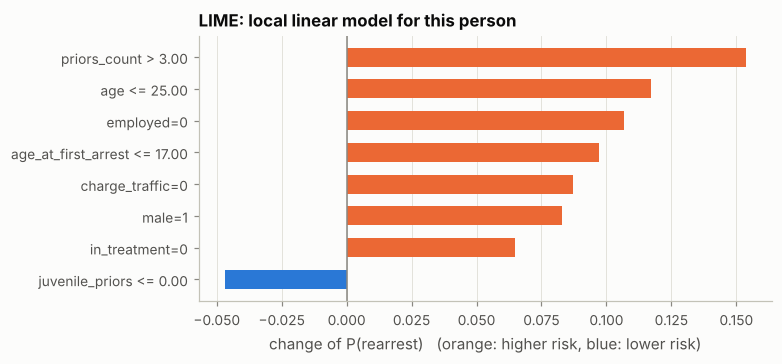

local model predicts 0.73, the opaque model 0.69
R2 of the local model on the weighted samples: 0.65


In [4]:
binary = [i for i, n in enumerate(names) if A_train[n].nunique() == 2]
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    A_train.to_numpy(),
    feature_names=names,
    class_names=["no rearrest", "rearrest"],
    categorical_features=binary,
    random_state=0,
)
explanation = lime_explainer.explain_instance(
    one_encoded.to_numpy()[0], gbm.predict_proba, num_features=8
)


def bars(ax, labels, values, title, xlabel):
    colors = [ORANGE if v > 0 else BLUE for v in values]
    ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.6)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="y", visible=False)


labels, values = zip(*explanation.as_list())
fig, ax = plt.subplots(figsize=(7, 3.2))
bars(
    ax,
    labels,
    values,
    "LIME: local linear model for this person",
    "change of P(rearrest)   (orange: higher risk, blue: lower risk)",
)
plt.show()
print(
    f"local model predicts {explanation.local_pred[0]:.2f}, the opaque model {model.predict_proba(one)[0, 1]:.2f}"
)
print(f"R2 of the local model on the weighted samples: {explanation.score:.2f}")

LIME describes numeric features as ranges ("`priors_count > 3`"), so the explanation is short
and easy to read. But see the R²: the linear model describes the opaque model only roughly,
also near the person. `lime_stability.py` shows a second problem: the explanation changes
when you run LIME again.

## 3. SHAP: Shapley values

SHAP divides the difference between this prediction and the average prediction among the
features. The division comes from game theory (Shapley, 1953): the influence of a feature is
its average contribution over all orders in which the features can be "added". For trees,
`TreeExplainer` computes the values exactly and fast. The unit is log-odds.

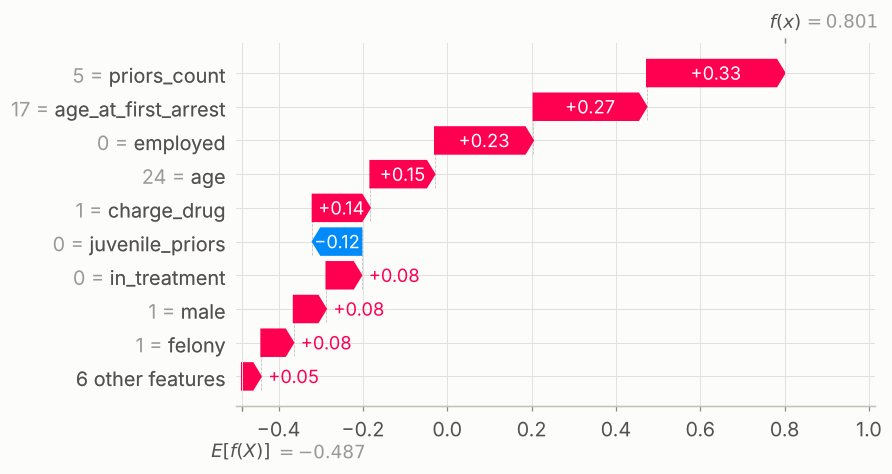

average log-odds -0.49 + sum of the SHAP values +1.29 = +0.80
log-odds of the model for this person: +0.80  ->  P = 0.69


In [5]:
shap_explainer = shap.TreeExplainer(gbm)
shap_one = shap_explainer(one_encoded)[0]
shap.plots.waterfall(shap_one, max_display=10, show=False)
plt.gcf().set_size_inches(8, 4.2)
plt.show()

total = shap_one.base_values + shap_one.values.sum()
print(
    f"average log-odds {shap_one.base_values:+.2f} + sum of the SHAP values {shap_one.values.sum():+.2f} = {total:+.2f}"
)
print(
    f"log-odds of the model for this person: {gbm.decision_function(one_encoded)[0]:+.2f}  ->  P = {1 / (1 + np.exp(-total)):.2f}"
)

The values add up to the prediction exactly. And each feature gets a value: the explanation
is complete, but not sparse.

The same explanation as a **force plot**:

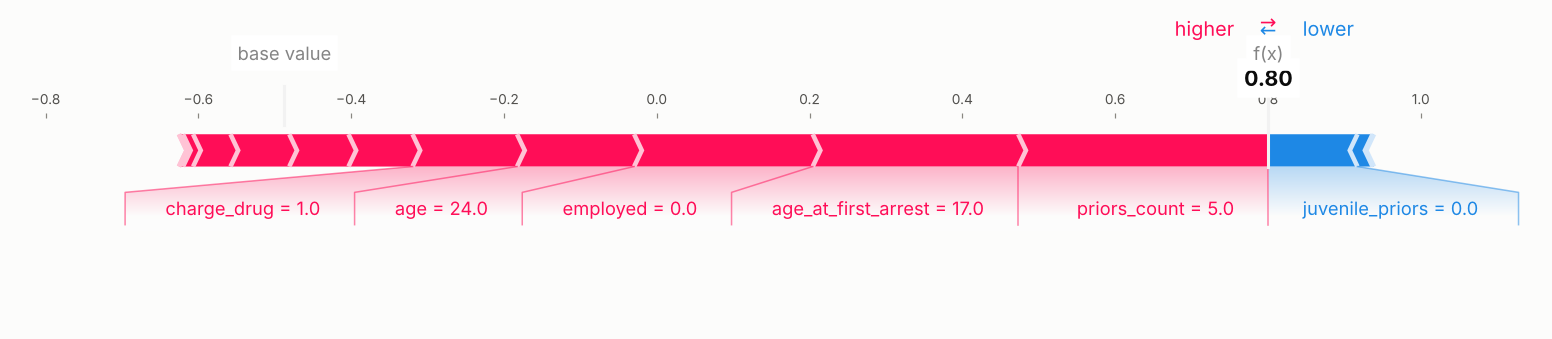

In [6]:
with plt.rc_context({"axes.grid": False}):
    shap.plots.force(
        shap_one, matplotlib=True, show=False, figsize=(14, 2.8), contribution_threshold=0.1
    )
    plt.show()

### Is the explanation true?

The data is synthetic, so we know the true contribution of each feature for this person: the
term of the feature in the true process, minus the average of that term over all people.

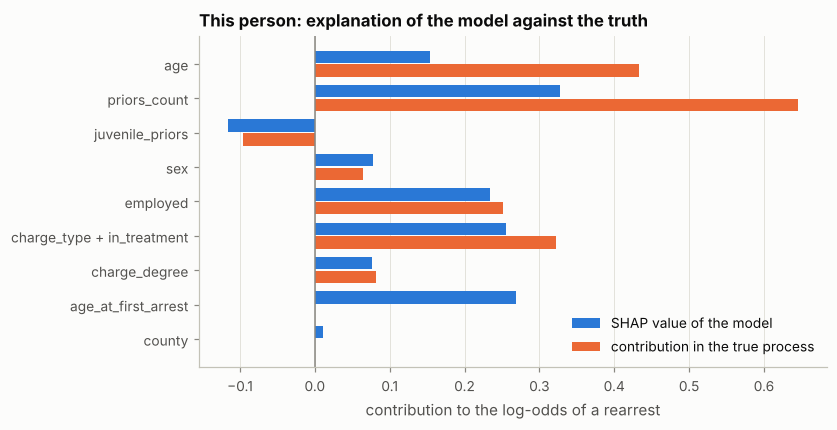

,SHAP of the model,true process
age,0.15,0.43
priors_count,0.33,0.65
juvenile_priors,-0.12,-0.10
sex,0.08,0.06
employed,0.23,0.25
charge_type + in_treatment,0.26,0.32
charge_degree,0.08,0.08
age_at_first_arrest,0.27,0.00
county,0.01,0.00


In [7]:
def true_contributions(row: pd.DataFrame) -> pd.Series:
    people = X_train.sample(2000, random_state=0)
    result = {}
    for group in [
        ["age"],
        ["priors_count"],
        ["juvenile_priors"],
        ["sex"],
        ["employed"],
        ["charge_type", "in_treatment"],
        ["charge_degree"],
        ["age_at_first_arrest"],
        ["county"],
    ]:
        replaced = people.copy()
        for feature in group:
            replaced[feature] = row[feature].iloc[0]
        result[" + ".join(group)] = (true_logit(replaced) - true_logit(people)).mean()
    return pd.Series(result)


def grouped_shap(values: np.ndarray) -> pd.Series:
    s = pd.Series(values, index=names)
    charge = s[[n for n in names if n.startswith("charge_")]].sum() + s["in_treatment"]
    county = s[[n for n in names if n.startswith("county_")]].sum()
    return pd.Series(
        {
            "age": s["age"],
            "priors_count": s["priors_count"],
            "juvenile_priors": s["juvenile_priors"],
            "sex": s["male"],
            "employed": s["employed"],
            "charge_type + in_treatment": charge,
            "charge_degree": s["felony"],
            "age_at_first_arrest": s["age_at_first_arrest"],
            "county": county,
        }
    )


compare = pd.DataFrame(
    {"SHAP of the model": grouped_shap(shap_one.values), "true process": true_contributions(one)}
)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(compare))
ax.barh(
    y - 0.2, compare["SHAP of the model"], height=0.36, color=BLUE, label="SHAP value of the model"
)
ax.barh(
    y + 0.2,
    compare["true process"],
    height=0.36,
    color=ORANGE,
    label="contribution in the true process",
)
ax.set_yticks(y, compare.index)
ax.invert_yaxis()
ax.axvline(0, color=MUTED, linewidth=1)
ax.set(
    title="This person: explanation of the model against the truth",
    xlabel="contribution to the log-odds of a rearrest",
)
ax.grid(axis="y", visible=False)
ax.legend()
plt.show()
compare.round(2)

SHAP is a **faithful description of the model**: the model does use `age_at_first_arrest`.
But it is not a description of the world. For this person, the true process puts a larger
effect on `priors_count` and none on `age_at_first_arrest`. A judge who reads "first arrest at
17 increases the risk" gets a statement about the model.

## 4. From single predictions back to the whole model

Compute the SHAP values for many people. Each dot is one person and one feature.

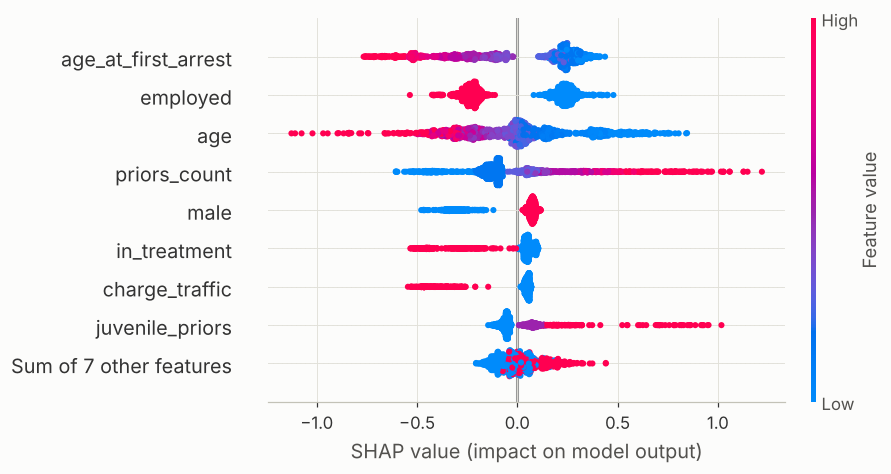

In [8]:
shap_test = shap_explainer(A_test.sample(1500, random_state=0))
shap.plots.beeswarm(shap_test, max_display=9, show=False, plot_size=(8, 4.2))
plt.show()

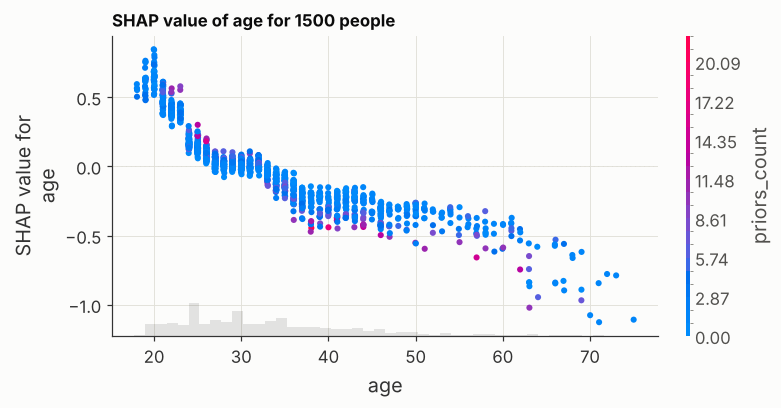

In [9]:
shap.plots.scatter(shap_test[:, "age"], color=shap_test[:, "priors_count"], show=False)
plt.gcf().set_size_inches(7, 3.6)
plt.title("SHAP value of age for 1500 people")
plt.show()

## 5. Feature influence is different for each person

The global ranking (mean absolute SHAP value) and the ranking for two people:

In [10]:
other = load().query("id == 8")[one.columns]  # a 62-year-old employed man, one prior, drug charge
shap_other = shap_explainer(onehot(other))[0]
ranking = pd.DataFrame(
    {
        "global: mean |SHAP|": pd.Series(np.abs(shap_test.values).mean(axis=0), index=names),
        f"person A (P = {model.predict_proba(one)[0, 1]:.2f})": pd.Series(
            shap_one.values, index=names
        ),
        f"person B (P = {model.predict_proba(other)[0, 1]:.2f})": pd.Series(
            shap_other.values, index=names
        ),
    }
)
ranking.sort_values("global: mean |SHAP|", ascending=False).head(8).round(2)

,global: mean |SHAP|,person A (P = 0.69),person B (P = 0.15)
age_at_first_arrest,0.28,0.27,-0.73
employed,0.24,0.23,-0.27
age,0.22,0.15,-0.45
priors_count,0.21,0.33,-0.11
male,0.12,0.08,0.08
in_treatment,0.10,0.08,0.09
charge_traffic,0.09,0.05,0.06
juvenile_priors,0.09,-0.12,-0.04
